# Pakistan Air Quality & Winter Smog Forecasting

End-to-end exploratory data analysis, leak-free next-day (`t+1`) **PM2.5** & **Winter Smog** forecasting across **30 major Pakistani cities** using CAMS air quality + ERA5 meteorology, and an interactive city dashboard.

### Dataset
- **File:** `dataset/pakistan_air_quality_daily.csv` (`47,190` rows × `29` columns, `2022-08-05` → `2026-11-24`, `30` cities across all provinces/territories, zero missing values)
- **Sources:** [Open-Meteo Air Quality API](https://open-meteo.com/en/docs/air-quality-api) (Copernicus CAMS global model) & [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) (ECMWF ERA5 reanalysis), integrated directly in Section 1 with automated validation and exception handling.

### Pipeline Overview
1. **Environment Setup, Data Acquisition & Validation** - Load `dataset/pakistan_air_quality_daily.csv` (or automatically fetch & aggregate from Open-Meteo when missing/corrupt/`REFRESH_DATASET=True`), enforce schema/range/null invariants with comprehensive edge-case exception handling, and derive calendar and meteorological inversion features (`temp_range`, `dew_point_spread`, `month`, `day_of_week`, `day_of_year`).
2. **Exploratory Data Analysis & Winter Smog Seasonality** - Compare pollutant and ERA5 weather correlations with `pm2_5_mean`, inspect PM2.5 AQI categories and winter smog (`Nov-Feb`) severity across cities (`visualizations/eda_overview.png`), and compute single-city PACF for `Lahore` (`visualizations/lahore_pacf.png`).
3. **City-Grouped Feature Engineering & Dual Modeling** - Build leak-free `city_id`-grouped lag (`1, 2, 3` days) and rolling (`3, 7` days) features across CAMS pollutants and ERA5 weather, split chronologically per city (`80/10/10`), train `LinearRegression` for next-day `pm2_5_mean` plus `LogisticRegression` (balanced pipeline) for next-day smog episodes (`PM2.5 >= 55.5 µg/m³`), evaluate overall, winter-smog, and per-city metrics (`visualizations/model_evaluation.png`, `visualizations/winter_smog_city_ranking.png`), and save `model/pakistan_aqi_smog_models.pkl`.
4. **Interactive Pakistan City & Winter Smog Dashboard** - Inspect next-day forecasts, smog episode risk across all 30 cities, 30-day trends (`visualizations/city_dashboard_overview.png`), and an interactive 30-city Folium map exported to `visualizations/pakistan_air_quality_map.html`.

## 1. Environment Setup, Data Acquisition & Validation

In [1]:
import os
import time
from math import sqrt
from pathlib import Path
from typing import Any, TypedDict

import folium
import ipywidgets as widgets
import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import HTML, IFrame, clear_output, display
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import pacf

os.makedirs('dataset', exist_ok=True)
os.makedirs('model', exist_ok=True)
os.makedirs('visualizations', exist_ok=True)

sns.set_theme(style='whitegrid')

DATASET_PATH = Path('dataset/pakistan_air_quality_daily.csv')
REFRESH_DATASET = False
START_DATE = '2022-08-05'
END_DATE = '2026-11-24'
TIMEZONE = 'Asia/Karachi'
SMOG_THRESHOLD_UGM3 = 55.5

AQ_URL = 'https://air-quality-api.open-meteo.com/v1/air-quality'
WX_URL = 'https://archive-api.open-meteo.com/v1/archive'
AQ_HOURLY_VARS = (
    'pm2_5,pm10,nitrogen_dioxide,sulphur_dioxide,'
    'ozone,carbon_monoxide,dust,aerosol_optical_depth,us_aqi'
)
WX_HOURLY_VARS = (
    'temperature_2m,relative_humidity_2m,dew_point_2m,'
    'precipitation,surface_pressure,cloud_cover,wind_speed_10m'
)

PAKISTAN_CITIES: list[tuple[str, str, float, float]] = [
    ('Abbottabad', 'Khyber Pakhtunkhwa', 34.1688, 73.2215),
    ('Bahawalpur', 'Punjab', 29.3544, 71.6911),
    ('Dera Ghazi Khan', 'Punjab', 30.0489, 70.6455),
    ('Dera Ismail Khan', 'Khyber Pakhtunkhwa', 31.8626, 70.9019),
    ('Faisalabad', 'Punjab', 31.4504, 73.1350),
    ('Gilgit', 'Gilgit-Baltistan', 35.9208, 74.3080),
    ('Gujranwala', 'Punjab', 32.1877, 74.1945),
    ('Gujrat', 'Punjab', 32.5731, 74.0750),
    ('Gwadar', 'Balochistan', 25.1216, 62.3254),
    ('Hyderabad', 'Sindh', 25.3960, 68.3578),
    ('Islamabad', 'Islamabad Capital Territory', 33.6844, 73.0479),
    ('Jhang', 'Punjab', 31.2781, 72.3317),
    ('Karachi', 'Sindh', 24.8607, 67.0011),
    ('Kasur', 'Punjab', 31.1179, 74.4408),
    ('Lahore', 'Punjab', 31.5204, 74.3587),
    ('Larkana', 'Sindh', 27.5570, 68.2028),
    ('Mardan', 'Khyber Pakhtunkhwa', 34.1986, 72.0404),
    ('Mingora', 'Khyber Pakhtunkhwa', 34.7717, 72.3602),
    ('Multan', 'Punjab', 30.1575, 71.5249),
    ('Muzaffarabad', 'Azad Kashmir', 34.3700, 73.4711),
    ('Nawabshah', 'Sindh', 26.2442, 68.4100),
    ('Peshawar', 'Khyber Pakhtunkhwa', 34.0151, 71.5249),
    ('Quetta', 'Balochistan', 30.1798, 66.9750),
    ('Rahim Yar Khan', 'Punjab', 28.4212, 70.2989),
    ('Rawalpindi', 'Punjab', 33.5651, 73.0169),
    ('Sahiwal', 'Punjab', 30.6682, 73.1114),
    ('Sargodha', 'Punjab', 32.0740, 72.6861),
    ('Sheikhupura', 'Punjab', 31.7167, 73.9850),
    ('Sialkot', 'Punjab', 32.4945, 74.5229),
    ('Sukkur', 'Sindh', 27.7052, 68.8574),
]

REQUIRED_COLUMNS = [
    'date', 'city', 'province', 'latitude', 'longitude',
    'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max',
    'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max',
    'dust_mean', 'aod_mean', 'us_aqi_max', 'hours_available',
    'temp_mean', 'temp_min', 'temp_max', 'dew_point_mean',
    'humidity_mean', 'wind_speed_mean', 'pressure_mean',
    'precip_sum', 'cloud_cover_mean', 'pm25_aqi_category',
    'is_winter_smog_season', 'is_smog_day',
]

NON_NEGATIVE_COLS = [
    'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max',
    'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max',
    'dust_mean', 'aod_mean', 'us_aqi_max', 'wind_speed_mean', 'precip_sum',
]

In [2]:
class DatasetValidationError(ValueError):
    """Raised when the air quality dataset fails schema or integrity checks."""


def _get_json_with_retry(
    session: requests.Session, url: str, params: dict[str, str | float], max_attempts: int = 6
) -> dict[str, Any] | list[dict[str, Any]]:
    """Perform HTTP GET with retry/backoff for rate limits, timeouts, and server errors."""
    last_error: Exception | None = None
    for attempt in range(max_attempts):
        try:
            resp = session.get(url, params=params, timeout=60)
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as exc:
            last_error = exc
            time.sleep(min(60, 5 * (2**attempt)))
            continue
        except requests.exceptions.RequestException as exc:
            raise RuntimeError(f"HTTP request failed for {url}: {exc}") from exc

        if resp.status_code == 429 or resp.status_code >= 500:
            retry_after = resp.headers.get('Retry-After', '').strip()
            wait_s = int(retry_after) if retry_after.isdigit() else min(60, 5 * (2**attempt))
            last_error = RuntimeError(f"HTTP {resp.status_code} from {url}")
            time.sleep(wait_s)
            continue

        if resp.status_code >= 400:
            raise RuntimeError(f"Non-retryable HTTP {resp.status_code} from {url}: {resp.text[:250]}")

        try:
            payload = resp.json()
        except ValueError as exc:
            raise ValueError(f"Invalid JSON returned by {url}") from exc

        if isinstance(payload, dict) and payload.get('error'):
            reason = str(payload.get('reason', 'Unknown Open-Meteo API error'))
            raise RuntimeError(f"Open-Meteo API error for {url}: {reason}")
        return payload

    raise RuntimeError(f"Exhausted {max_attempts} retries for {url}: {last_error}")


def _classify_pm25_category(val: float) -> str:
    """Classify daily mean PM2.5 (µg/m³) using US EPA / Pakistan AQI breakpoints."""
    if not np.isfinite(val) or val < 0:
        raise DatasetValidationError(f"Invalid PM2.5 value for AQI classification: {val!r}")
    if val <= 12.0:
        return 'Good'
    if val <= 35.4:
        return 'Moderate'
    if val <= 55.4:
        return 'Unhealthy for Sensitive'
    if val <= 150.4:
        return 'Unhealthy'
    if val <= 250.4:
        return 'Very Unhealthy'
    return 'Hazardous'


def _build_hourly_frame(hourly_payload: dict[str, Any], expected_cols: list[str], source: str) -> pd.DataFrame:
    """Validate hourly JSON payload keys and array lengths before building a DataFrame."""
    if not isinstance(hourly_payload, dict):
        raise DatasetValidationError(f"{source} hourly payload must be a dict, got {type(hourly_payload).__name__}")
    missing = [col for col in expected_cols if col not in hourly_payload]
    if missing:
        raise DatasetValidationError(f"{source} hourly payload missing keys: {missing}")

    lengths = {col: len(hourly_payload[col]) for col in expected_cols}
    if len(set(lengths.values())) != 1 or next(iter(lengths.values())) == 0:
        raise DatasetValidationError(f"{source} hourly payload has empty or mismatched arrays: {lengths}")
    return pd.DataFrame(hourly_payload)


def _aggregate_city_daily(
    aq_hourly: dict[str, Any], wx_hourly: dict[str, Any], city: str, province: str, lat: float, lon: float
) -> pd.DataFrame:
    """Aggregate hourly CAMS air quality + ERA5 weather dicts with edge-case safeguards."""
    aq_cols = ['time', *AQ_HOURLY_VARS.split(',')]
    wx_cols = ['time', *WX_HOURLY_VARS.split(',')]
    aq_df = _build_hourly_frame(aq_hourly, aq_cols, f"{city} AQ").drop_duplicates(subset=['time'])
    wx_df = _build_hourly_frame(wx_hourly, wx_cols, f"{city} Weather").drop_duplicates(subset=['time'])

    merged = aq_df.merge(wx_df, on='time', how='inner')
    if merged.empty:
        raise DatasetValidationError(f"No overlapping hourly timestamps between AQ and Weather for {city}")

    merged['dt'] = pd.to_datetime(merged['time'], format='%Y-%m-%dT%H:%M', errors='coerce')
    merged = merged.dropna(subset=['dt']).sort_values('dt').reset_index(drop=True)
    if merged.empty:
        raise DatasetValidationError(f"All timestamps failed parsing for {city}")

    numeric_hourly = [c for c in [*AQ_HOURLY_VARS.split(','), *WX_HOURLY_VARS.split(',')] if c in merged.columns]
    for col in numeric_hourly:
        merged[col] = pd.to_numeric(merged[col], errors='coerce')
    merged[numeric_hourly] = merged[numeric_hourly].replace([np.inf, -np.inf], np.nan)

    # Drop incomplete trailing/corrupt hours for core fields; fill short isolated us_aqi gaps
    core_hourly = [c for c in numeric_hourly if c != 'us_aqi']
    merged = merged.dropna(subset=core_hourly).copy()
    if merged.empty:
        raise DatasetValidationError(f"No valid non-null hourly observations remained for {city}")

    merged['o3_8h'] = merged['ozone'].rolling(8, min_periods=1).mean()
    merged['co_8h'] = merged['carbon_monoxide'].rolling(8, min_periods=1).mean()
    merged['date'] = merged['dt'].dt.strftime('%Y-%m-%d')

    daily = (
        merged.groupby('date', as_index=False)
        .agg(
            pm2_5_mean=('pm2_5', 'mean'),
            pm2_5_max=('pm2_5', 'max'),
            pm10_mean=('pm10', 'mean'),
            pm10_max=('pm10', 'max'),
            no2_mean=('nitrogen_dioxide', 'mean'),
            so2_mean=('sulphur_dioxide', 'mean'),
            o3_8h_max=('o3_8h', 'max'),
            co_8h_max=('co_8h', 'max'),
            dust_mean=('dust', 'mean'),
            aod_mean=('aerosol_optical_depth', 'mean'),
            us_aqi_max=('us_aqi', 'max'),
            hours_available=('pm2_5', 'count'),
            temp_mean=('temperature_2m', 'mean'),
            temp_min=('temperature_2m', 'min'),
            temp_max=('temperature_2m', 'max'),
            dew_point_mean=('dew_point_2m', 'mean'),
            humidity_mean=('relative_humidity_2m', 'mean'),
            wind_speed_mean=('wind_speed_10m', 'mean'),
            pressure_mean=('surface_pressure', 'mean'),
            precip_sum=('precipitation', 'sum'),
            cloud_cover_mean=('cloud_cover', 'mean'),
        )
        .sort_values('date')
        .reset_index(drop=True)
    )

    daily = daily[daily['hours_available'] >= 18].copy()
    if daily['us_aqi_max'].isna().any():
        daily['us_aqi_max'] = daily['us_aqi_max'].ffill().bfill()

    daily.insert(1, 'city', city)
    daily.insert(2, 'province', province)
    daily.insert(3, 'latitude', lat)
    daily.insert(4, 'longitude', lon)

    for col in NON_NEGATIVE_COLS:
        daily[col] = daily[col].clip(lower=0.0)
    daily['humidity_mean'] = daily['humidity_mean'].clip(0.0, 100.0)
    daily['cloud_cover_mean'] = daily['cloud_cover_mean'].clip(0.0, 100.0)

    daily['pm25_aqi_category'] = daily['pm2_5_mean'].map(_classify_pm25_category)
    months = pd.to_datetime(daily['date'], format='%Y-%m-%d').dt.month
    daily['is_winter_smog_season'] = months.isin([11, 12, 1, 2]).astype(int)
    daily['is_smog_day'] = (daily['pm2_5_mean'] >= SMOG_THRESHOLD_UGM3).astype(int)

    float_cols = daily.select_dtypes(include=[np.floating]).columns
    daily[float_cols] = daily[float_cols].round(2)
    return daily


def fetch_batch_daily(
    session: requests.Session, batch: list[tuple[str, str, float, float]]
) -> list[pd.DataFrame]:
    """Fetch a multi-city batch from Open-Meteo AQ and ERA5 APIs."""
    if not batch:
        raise DatasetValidationError('City batch cannot be empty')
    lats = ','.join(str(item[2]) for item in batch)
    lons = ','.join(str(item[3]) for item in batch)

    aq_raw = _get_json_with_retry(
        session,
        AQ_URL,
        {
            'latitude': lats,
            'longitude': lons,
            'hourly': AQ_HOURLY_VARS,
            'start_date': START_DATE,
            'end_date': END_DATE,
            'timezone': TIMEZONE,
        },
    )
    wx_raw = _get_json_with_retry(
        session,
        WX_URL,
        {
            'latitude': lats,
            'longitude': lons,
            'hourly': WX_HOURLY_VARS,
            'start_date': START_DATE,
            'end_date': END_DATE,
            'timezone': TIMEZONE,
        },
    )

    aq_list = aq_raw if isinstance(aq_raw, list) else [aq_raw]
    wx_list = wx_raw if isinstance(wx_raw, list) else [wx_raw]
    if len(aq_list) != len(batch) or len(wx_list) != len(batch):
        raise DatasetValidationError(
            f"Batch size mismatch: expected {len(batch)}, got AQ={len(aq_list)}, WX={len(wx_list)}"
        )

    out: list[pd.DataFrame] = []
    for (city, province, lat, lon), aq_item, wx_item in zip(batch, aq_list, wx_list):
        if 'hourly' not in aq_item or 'hourly' not in wx_item:
            raise DatasetValidationError(f"Missing 'hourly' block in response for {city}")
        out.append(_aggregate_city_daily(aq_item['hourly'], wx_item['hourly'], city, province, lat, lon))
    return out


def validate_and_clean_dataset(raw_df: pd.DataFrame) -> pd.DataFrame:
    """Validate schema, dates, duplicates, nulls, and physical bounds for the Pakistan dataset."""
    if raw_df.empty:
        raise DatasetValidationError('Dataset is empty')

    missing_cols = [col for col in REQUIRED_COLUMNS if col not in raw_df.columns]
    if missing_cols:
        raise DatasetValidationError(f"Dataset missing required columns: {missing_cols}")

    cleaned = raw_df.copy()
    cleaned['city'] = cleaned['city'].astype(str).str.strip()
    cleaned['province'] = cleaned['province'].astype(str).str.strip()
    if (cleaned['city'] == '').any() or (cleaned['province'] == '').any():
        raise DatasetValidationError('Dataset contains blank city or province names')

    parsed_dates = pd.to_datetime(cleaned['date'], format='%Y-%m-%d', errors='coerce')
    bad_dates = parsed_dates.isna().sum()
    if bad_dates > 0:
        raise DatasetValidationError(f"Dataset contains {bad_dates} unparseable date values")
    cleaned['date'] = parsed_dates

    numeric_cols = [c for c in REQUIRED_COLUMNS if c not in ('date', 'city', 'province', 'pm25_aqi_category')]
    for col in numeric_cols:
        cleaned[col] = pd.to_numeric(cleaned[col], errors='coerce')
    cleaned[numeric_cols] = cleaned[numeric_cols].replace([np.inf, -np.inf], np.nan)

    null_counts = cleaned[REQUIRED_COLUMNS].isna().sum()
    if int(null_counts.sum()) > 0:
        bad_cols = null_counts[null_counts > 0].to_dict()
        raise DatasetValidationError(f"Dataset contains missing/non-finite values: {bad_cols}")

    cleaned = cleaned.sort_values(['city', 'date']).drop_duplicates(subset=['city', 'date'], keep='last').reset_index(drop=True)

    if cleaned['city'].nunique() < len(PAKISTAN_CITIES):
        raise DatasetValidationError(
            f"Expected at least {len(PAKISTAN_CITIES)} cities, found {cleaned['city'].nunique()}"
        )
    if not cleaned['hours_available'].between(18, 24).all():
        raise DatasetValidationError('Found days with hours_available outside [18, 24]')
    if not cleaned['latitude'].between(23.0, 38.0).all() or not cleaned['longitude'].between(60.0, 78.0).all():
        raise DatasetValidationError('Found city coordinates outside Pakistan geographic bounds')
    for col in NON_NEGATIVE_COLS:
        if (cleaned[col] < 0).any():
            raise DatasetValidationError(f"Column {col} contains negative values")
    if not cleaned['humidity_mean'].between(0.0, 100.0).all() or not cleaned['cloud_cover_mean'].between(0.0, 100.0).all():
        raise DatasetValidationError('Humidity or cloud cover outside [0, 100]')
    if (cleaned['temp_max'] < cleaned['temp_min']).any():
        raise DatasetValidationError('Found rows where temp_max < temp_min')
    return cleaned


def fetch_pakistan_dataset(output_path: Path = DATASET_PATH, batch_size: int = 5) -> pd.DataFrame:
    """Fetch all 30 Pakistani cities from Open-Meteo and atomically persist the validated CSV."""
    output_path.parent.mkdir(parents=True, exist_ok=True)
    frames: list[pd.DataFrame] = []

    with requests.Session() as session:
        for start in range(0, len(PAKISTAN_CITIES), batch_size):
            batch = PAKISTAN_CITIES[start : start + batch_size]
            batch_frames = fetch_batch_daily(session, batch)
            frames.extend(batch_frames)
            time.sleep(2.0)

    full_df = pd.concat(frames, ignore_index=True).sort_values(['city', 'date']).reset_index(drop=True)
    validated_df = validate_and_clean_dataset(full_df)
    export_df = validated_df.copy()
    export_df['date'] = export_df['date'].dt.strftime('%Y-%m-%d')

    tmp_path = output_path.with_suffix('.csv.tmp')
    export_df.to_csv(tmp_path, index=False)
    os.replace(tmp_path, output_path)
    return validated_df


def load_or_fetch_pakistan_dataset(
    csv_path: Path = DATASET_PATH, refresh: bool = REFRESH_DATASET
) -> pd.DataFrame:
    """Load local Pakistan dataset with corruption recovery and Open-Meteo fallback."""
    cached_df: pd.DataFrame | None = None
    if csv_path.is_file() and csv_path.stat().st_size > 0:
        try:
            raw_df = pd.read_csv(csv_path, encoding='utf-8')
            cached_df = validate_and_clean_dataset(raw_df)
        except (pd.errors.EmptyDataError, pd.errors.ParserError, UnicodeDecodeError, OSError, DatasetValidationError) as exc:
            print(f"Warning: Local dataset at {csv_path} could not be validated ({exc}). Re-fetching from Open-Meteo...")

    if cached_df is not None and not refresh:
        return cached_df

    try:
        return fetch_pakistan_dataset(csv_path)
    except Exception as exc:
        if cached_df is not None:
            print(f"Warning: Open-Meteo refresh failed ({exc}). Falling back to validated local cache.")
            return cached_df
        raise RuntimeError(
            f"Unable to load local dataset ({csv_path}) or fetch fresh data from Open-Meteo: {exc}"
        ) from exc


df = load_or_fetch_pakistan_dataset(DATASET_PATH, refresh=REFRESH_DATASET)

CITY_MAP = {c: i for i, c in enumerate(sorted(df['city'].unique()))}
df['city_id'] = df['city'].map(CITY_MAP)
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.day_of_week
df['day_of_year'] = df['date'].dt.day_of_year
df['temp_range'] = (df['temp_max'] - df['temp_min']).round(2)
df['dew_point_spread'] = (df['temp_mean'] - df['dew_point_mean']).round(2)
df = df.sort_values(['city_id', 'date']).reset_index(drop=True)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date range: {df['date'].min().date()} -> {df['date'].max().date()} | Cities: {df['city'].nunique()}")
print(f"Total missing values: {int(df.isna().sum().sum())}")
print(f"Smog days (PM2.5 >= {SMOG_THRESHOLD_UGM3} µg/m³): {int(df['is_smog_day'].sum()):,} ({df['is_smog_day'].mean() * 100:.1f}%)")
df.head(3)

Dataset shape: 47,190 rows x 35 columns
Date range: 2022-08-05 -> 2026-11-24 | Cities: 30
Total missing values: 0
Smog days (PM2.5 >= 55.5 µg/m³): 12,287 (26.0%)


,date,city,province,latitude,longitude,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,...,cloud_cover_mean,pm25_aqi_category,is_winter_smog_season,is_smog_day,city_id,month,day_of_week,day_of_year,temp_range,dew_point_spread
0,2022-08-05,Abbottabad,Khyber Pakhtunkhwa,34.17,73.22,36.58,42.7,52.82,61.9,23.45,...,38.83,Unhealthy for Sensitive,0,0,0,8,4,217,5.7,4.01
1,2022-08-06,Abbottabad,Khyber Pakhtunkhwa,34.17,73.22,27.26,39.7,39.12,56.8,21.91,...,53.58,Moderate,0,0,0,8,5,218,6.3,2.67
2,2022-08-07,Abbottabad,Khyber Pakhtunkhwa,34.17,73.22,34.52,44.6,49.56,63.8,28.85,...,23.50,Moderate,0,0,0,8,6,219,7.4,3.57


## 2. Exploratory Data Analysis (EDA) & Winter Smog Seasonality

Examine CAMS pollutant and ERA5 meteorological correlations with `pm2_5_mean`, Pakistan PM2.5 AQI category distributions, winter smog (`Nov-Feb`) vs. non-winter city severity, and single-city PACF (`Lahore`) to verify lag depth.

Correlation with pm2_5_mean (pollutants + ERA5 weather):


pm2_5_mean          1.0000
pm2_5_max           0.9627
so2_mean            0.6871
pm10_mean           0.6706
co_8h_max           0.6622
no2_mean            0.5232
aod_mean            0.3958
pressure_mean       0.3496
humidity_mean       0.2986
o3_8h_max           0.2442
precip_sum         -0.1216
wind_speed_mean    -0.2175
temp_mean          -0.2652
dew_point_spread   -0.2789
Name: pm2_5_mean, dtype: float64

Seasonal PM2.5 comparison:


,count,mean,median
Non-Winter (Mar-Oct),32040,36.37,33.09
Winter Smog (Nov-Feb),15150,68.18,56.73


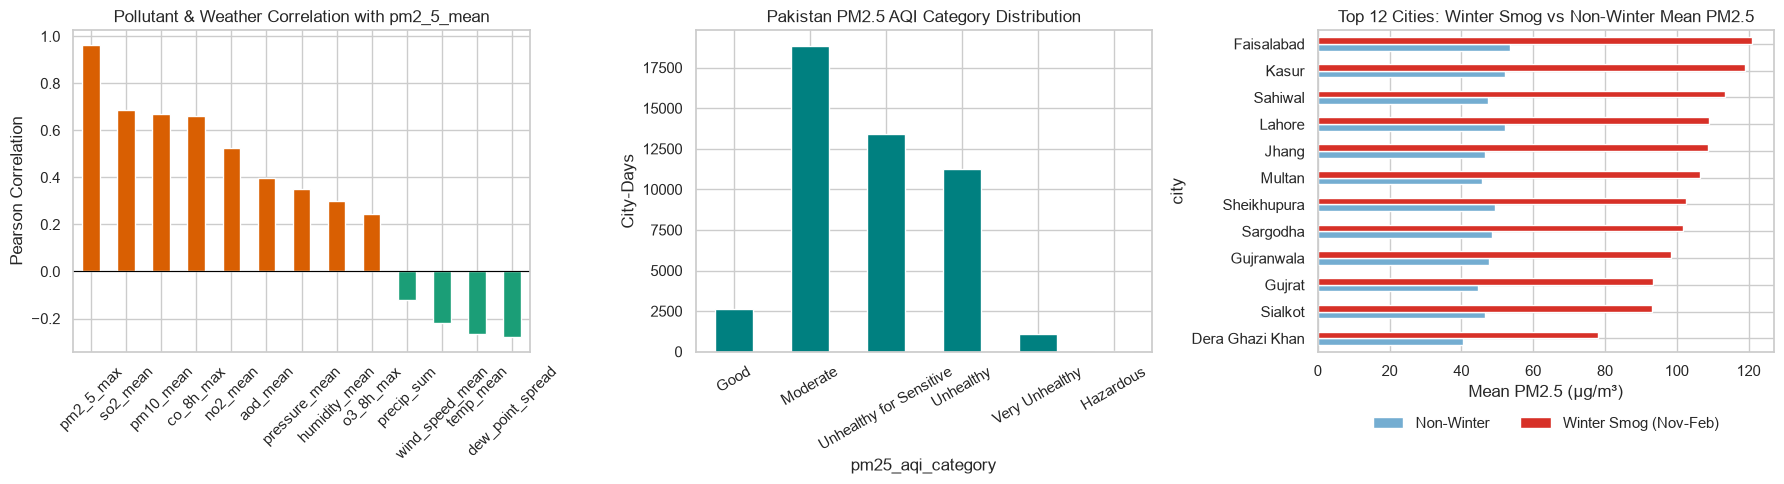

In [3]:
analysis_cols = [
    'pm2_5_mean', 'pm2_5_max', 'so2_mean', 'pm10_mean', 'co_8h_max',
    'no2_mean', 'aod_mean', 'pressure_mean', 'humidity_mean', 'o3_8h_max',
    'temp_mean', 'wind_speed_mean', 'precip_sum', 'dew_point_spread',
]

corr = df[analysis_cols].corr()['pm2_5_mean'].sort_values(ascending=False)
print("Correlation with pm2_5_mean (pollutants + ERA5 weather):")
display(corr.round(4))

winter_stats = df.groupby('is_winter_smog_season')['pm2_5_mean'].agg(['count', 'mean', 'median']).round(2)
winter_stats.index = pd.Index(['Non-Winter (Mar-Oct)', 'Winter Smog (Nov-Feb)'])
print("Seasonal PM2.5 comparison:")
display(winter_stats)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

corr_vals = corr.drop('pm2_5_mean')
corr_colors = ['#d95f02' if v > 0 else '#1b9e77' for v in corr_vals.values]
corr_vals.plot(kind='bar', ax=axes[0], color=corr_colors)
axes[0].set_title('Pollutant & Weather Correlation with pm2_5_mean')
axes[0].set_ylabel('Pearson Correlation')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].tick_params(axis='x', rotation=45)

cat_order = [
    'Good', 'Moderate', 'Unhealthy for Sensitive',
    'Unhealthy', 'Very Unhealthy', 'Hazardous',
]
cat_counts = df['pm25_aqi_category'].value_counts().reindex(cat_order, fill_value=0)
cat_counts.plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('Pakistan PM2.5 AQI Category Distribution')
axes[1].set_ylabel('City-Days')
axes[1].tick_params(axis='x', rotation=30)

city_season = (
    df.groupby(['city', 'is_winter_smog_season'])['pm2_5_mean']
    .mean()
    .unstack(fill_value=0)
    .rename(columns={0: 'Non-Winter', 1: 'Winter Smog (Nov-Feb)'})
)
top12_cities = city_season.sort_values('Winter Smog (Nov-Feb)', ascending=False).head(12)
top12_cities.iloc[::-1].plot(kind='barh', ax=axes[2], color=['#74add1', '#d73027'])
axes[2].set_title('Top 12 Cities: Winter Smog vs Non-Winter Mean PM2.5')
axes[2].set_xlabel('Mean PM2.5 (µg/m³)')
axes[2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)

plt.tight_layout()
fig.savefig('visualizations/eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

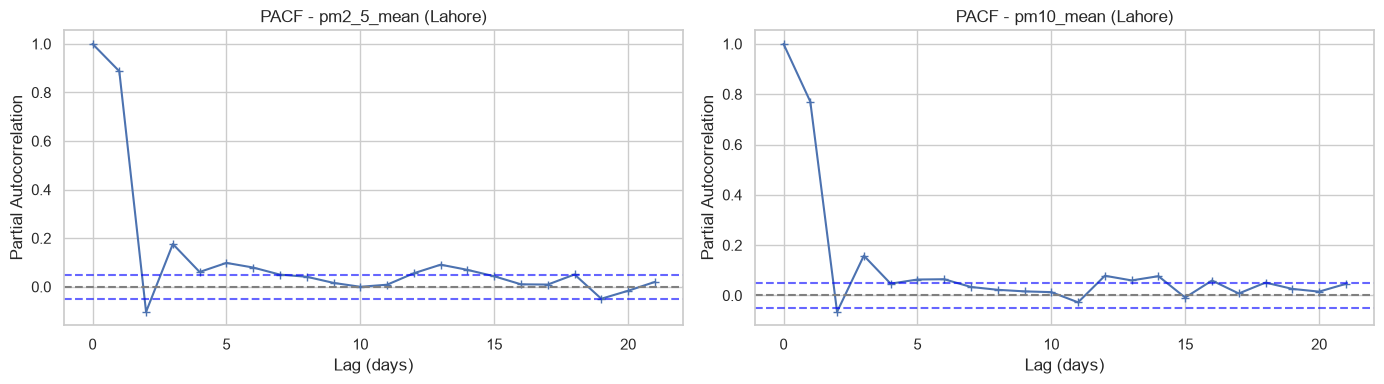

In [4]:
# Single-city PACF (Lahore) to avoid cross-city boundary artifacts
lahore_df = df[df['city'] == 'Lahore'].sort_values('date')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['pm2_5_mean', 'pm10_mean']):
    series = lahore_df[col].to_numpy(dtype=float)
    lag_pacf = pacf(series, nlags=21, method='ols')
    conf = 1.96 / np.sqrt(len(series))
    ax.plot(lag_pacf, marker='+')
    ax.axhline(0, linestyle='dashed', color='gray')
    ax.axhline(-conf, linestyle='dashed', color='blue', alpha=0.6)
    ax.axhline(conf, linestyle='dashed', color='blue', alpha=0.6)
    ax.set_title(f'PACF - {col} (Lahore)')
    ax.set_xlabel('Lag (days)')
    ax.set_ylabel('Partial Autocorrelation')

plt.tight_layout()
fig.savefig('visualizations/lahore_pacf.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. City-Grouped Feature Engineering, Next-Day (`t+1`) PM2.5 & Winter Smog Forecasting

### Pipeline Guarantees
- **No cross-city leakage:** All `shift()` and `rolling()` operations execute strictly inside `groupby('city_id')`.
- **Contiguous daily transitions:** Verifies exact 1-day spacing across lags (`1, 2, 3` days) and next-day (`t+1`) targets (`target_pm25` and `target_smog_day`).
- **Pollution + ERA5 meteorology:** Uses day-`t` CAMS pollutants, ERA5 weather (temperature, dew-point spread, humidity, wind speed, pressure, precipitation, cloud cover), city coordinates, winter smog season flag, and past lags/rolling averages, while excluding target-derived AQI summary labels (`us_aqi_max`, `pm25_aqi_category`, `is_smog_day`).
- **Chronological per-city split:** `80%` Train / `10%` Validation / `10%` Test ordered by `date` within each of the 30 Pakistani cities.

In [5]:
BASE_FEATURE_COLS = [
    'city_id', 'latitude', 'longitude',
    'month', 'day_of_week', 'day_of_year', 'is_winter_smog_season',
    'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max',
    'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max',
    'dust_mean', 'aod_mean',
    'temp_mean', 'temp_min', 'temp_range', 'dew_point_spread',
    'humidity_mean', 'wind_speed_mean', 'pressure_mean',
    'precip_sum', 'cloud_cover_mean',
]
LAG_SOURCE_COLS = [
    'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'no2_mean', 'so2_mean',
    'o3_8h_max', 'co_8h_max', 'dust_mean', 'aod_mean',
    'temp_mean', 'humidity_mean', 'wind_speed_mean', 'pressure_mean',
    'dew_point_spread',
]
ROLLING_COLS = [
    'pm2_5_mean', 'pm10_mean', 'no2_mean', 'so2_mean',
    'aod_mean', 'temp_mean', 'humidity_mean', 'wind_speed_mean',
    'pressure_mean', 'dew_point_spread',
]


def create_engineered_features(data_df: pd.DataFrame, include_target: bool = True) -> pd.DataFrame:
    """Create city-grouped lag (1, 2, 3) and rolling (3, 7) features for PM2.5 & smog forecasting."""
    work = data_df.sort_values(['city_id', 'date']).copy()
    grouped = work.groupby('city_id', group_keys=False)

    day_diff_1 = grouped['date'].diff(1).dt.days
    day_diff_2 = grouped['date'].diff(2).dt.days
    day_diff_3 = grouped['date'].diff(3).dt.days

    lag1 = grouped[LAG_SOURCE_COLS].shift(1).add_suffix('_lag_1')
    lag2 = grouped[LAG_SOURCE_COLS].shift(2).add_suffix('_lag_2')
    lag3 = grouped[LAG_SOURCE_COLS].shift(3).add_suffix('_lag_3')

    roll3 = grouped[ROLLING_COLS].rolling(3).mean().reset_index(level=0, drop=True).add_suffix('_rolling_3')
    roll7 = grouped[ROLLING_COLS].rolling(7).mean().reset_index(level=0, drop=True).add_suffix('_rolling_7')

    result = pd.concat(
        [work[['date', 'city', 'province'] + BASE_FEATURE_COLS], lag1, lag2, lag3, roll3, roll7],
        axis=1,
    )
    valid_history = (day_diff_1 == 1) & (day_diff_2 == 2) & (day_diff_3 == 3)
    result = result.loc[valid_history].copy()

    if include_target:
        next_date = grouped['date'].shift(-1)
        result['target_pm25'] = grouped['pm2_5_mean'].shift(-1)
        result['target_smog_day'] = grouped['is_smog_day'].shift(-1)
        result['target_winter_season'] = grouped['is_winter_smog_season'].shift(-1)
        result = result.loc[(next_date - result['date']).dt.days == 1].copy()
        result['target_smog_day'] = result['target_smog_day'].astype(int)
        result['target_winter_season'] = result['target_winter_season'].astype(int)

    return result.dropna().reset_index(drop=True)


feat_df = create_engineered_features(df, include_target=True)
feat_df['_rank_pct'] = feat_df.groupby('city_id')['date'].rank(method='first', pct=True)

train_df = feat_df[feat_df['_rank_pct'] <= 0.80].drop(columns=['_rank_pct']).reset_index(drop=True)
valid_df = feat_df[(feat_df['_rank_pct'] > 0.80) & (feat_df['_rank_pct'] <= 0.90)].drop(columns=['_rank_pct']).reset_index(drop=True)
test_df = feat_df[feat_df['_rank_pct'] > 0.90].drop(columns=['_rank_pct']).reset_index(drop=True)

NON_FEATURE_COLS = {'date', 'city', 'province', 'target_pm25', 'target_smog_day', 'target_winter_season'}
FEATURE_COLUMNS = [c for c in train_df.columns if c not in NON_FEATURE_COLS]
print(f"Engineered features: {len(FEATURE_COLUMNS)}")
print(f"Chronological splits -> Train: {len(train_df):,} | Valid: {len(valid_df):,} | Test: {len(test_df):,}")
print(f"Winter Smog days in splits -> Train: {int(train_df['target_winter_season'].sum()):,} | Valid: {int(valid_df['target_winter_season'].sum()):,} | Test: {int(test_df['target_winter_season'].sum()):,}")

Engineered features: 88
Chronological splits -> Train: 37,560 | Valid: 4,710 | Test: 4,710
Winter Smog days in splits -> Train: 13,080 | Valid: 1,350 | Test: 720


In [6]:
# Train next-day PM2.5 regressor & winter smog episode classifier
pm25_model = LinearRegression()
pm25_model.fit(train_df[FEATURE_COLUMNS], train_df['target_pm25'])

smog_classifier = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)),
])
smog_classifier.fit(train_df[FEATURE_COLUMNS], train_df['target_smog_day'])


def evaluate_models(name: str, frame: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    preds = np.maximum(pm25_model.predict(frame[FEATURE_COLUMNS]), 0)
    y_true = frame['target_pm25']
    rmse_val = sqrt(mean_squared_error(y_true, preds))
    mae_val = mean_absolute_error(y_true, preds)
    r2_val = r2_score(y_true, preds)

    winter_mask = frame['target_winter_season'] == 1
    w_rmse = sqrt(mean_squared_error(y_true[winter_mask], preds[winter_mask]))
    w_mae = mean_absolute_error(y_true[winter_mask], preds[winter_mask])

    smog_probs = smog_classifier.predict_proba(frame[FEATURE_COLUMNS])[:, 1]
    roc = roc_auc_score(frame['target_smog_day'], smog_probs)
    pr_auc = average_precision_score(frame['target_smog_day'], smog_probs)

    print(
        f"{name:<11} | All -> RMSE: {rmse_val:5.2f}, MAE: {mae_val:5.2f}, R²: {r2_val:.4f} | "
        f"Winter -> RMSE: {w_rmse:5.2f}, MAE: {w_mae:5.2f} | "
        f"Smog ROC-AUC: {roc:.4f}, PR-AUC: {pr_auc:.4f}"
    )
    return preds, smog_probs


pred_val, prob_val = evaluate_models('Validation', valid_df)
pred_test, prob_test = evaluate_models('Test', test_df)

artifact = {
    'pm25_model': pm25_model,
    'smog_classifier': smog_classifier,
    'feature_columns': FEATURE_COLUMNS,
    'city_map': CITY_MAP,
    'smog_threshold_ugm3': SMOG_THRESHOLD_UGM3,
}
MODEL_PATH = 'model/pakistan_aqi_smog_models.pkl'
joblib.dump(artifact, MODEL_PATH)
print(f"Saved trained Pakistan AQ & Smog model artifact -> {MODEL_PATH}")

Validation  | All -> RMSE: 14.24, MAE:  9.10, R²: 0.8076 | Winter -> RMSE: 20.38, MAE: 13.55 | Smog ROC-AUC: 0.9487, PR-AUC: 0.8461
Test        | All -> RMSE: 13.35, MAE:  8.82, R²: 0.7723 | Winter -> RMSE: 22.05, MAE: 15.01 | Smog ROC-AUC: 0.9372, PR-AUC: 0.8598
Saved trained Pakistan AQ & Smog model artifact -> model/pakistan_aqi_smog_models.pkl


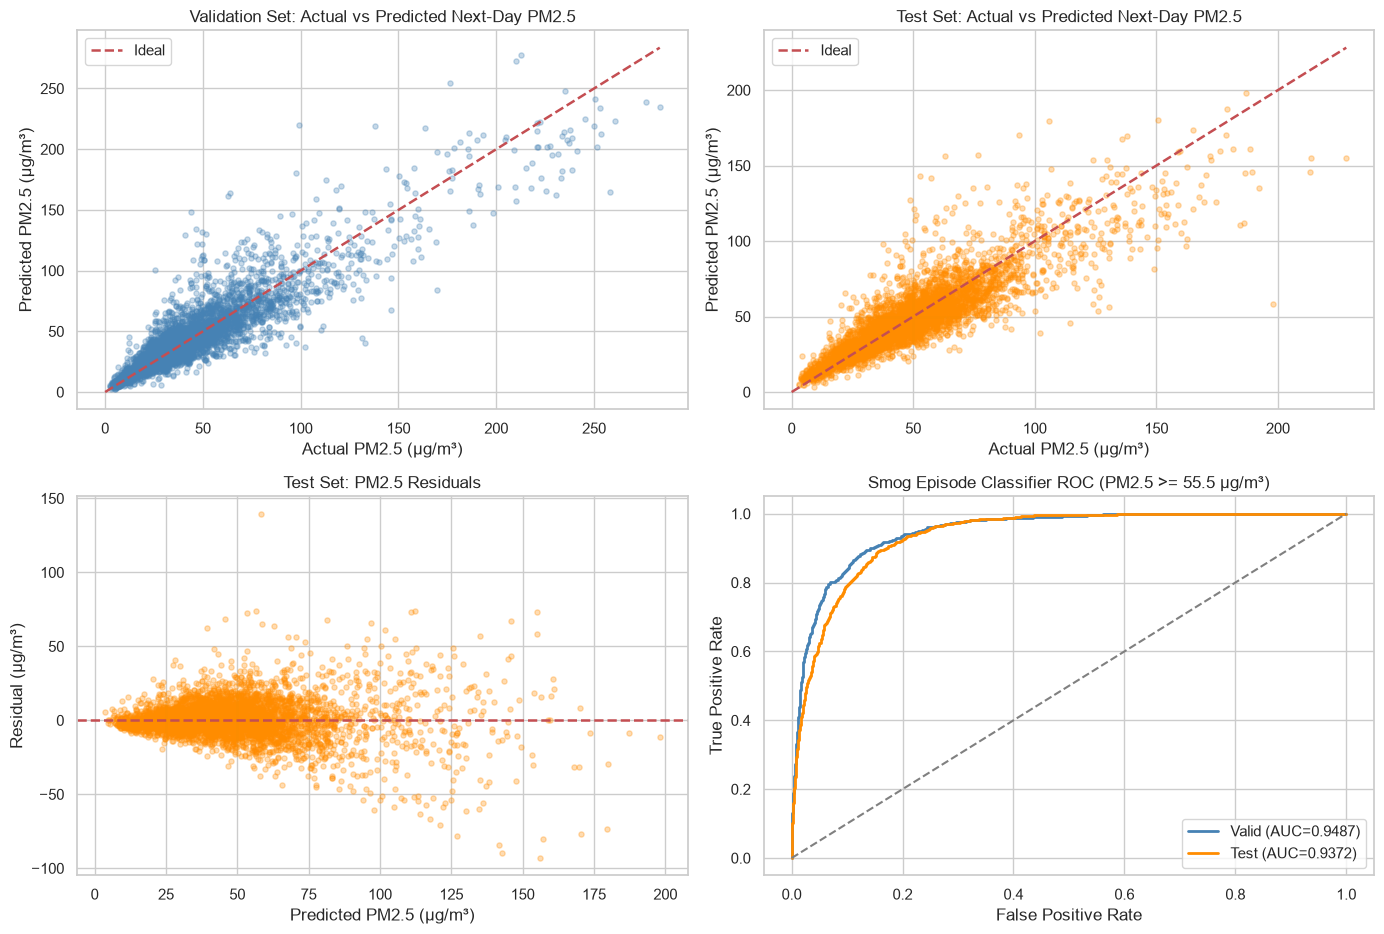

,City,Province,Test_RMSE,Test_MAE,Winter_Mean_Actual,Winter_Mean_Pred
0,Faisalabad,Punjab,21.88,14.96,126.38,124.30
1,Sahiwal,Punjab,18.72,12.84,121.12,115.59
2,Kasur,Punjab,24.00,16.39,117.80,114.46
3,Jhang,Punjab,18.47,12.72,115.25,109.51
4,Lahore,Punjab,19.52,14.32,103.58,101.46
5,Sheikhupura,Punjab,19.08,13.34,102.83,101.19
6,Multan,Punjab,15.74,11.35,102.21,97.57
7,Sargodha,Punjab,18.11,12.89,101.57,100.95
8,Gujranwala,Punjab,17.23,12.22,95.38,95.74
9,Sialkot,Punjab,14.93,11.30,87.24,87.13


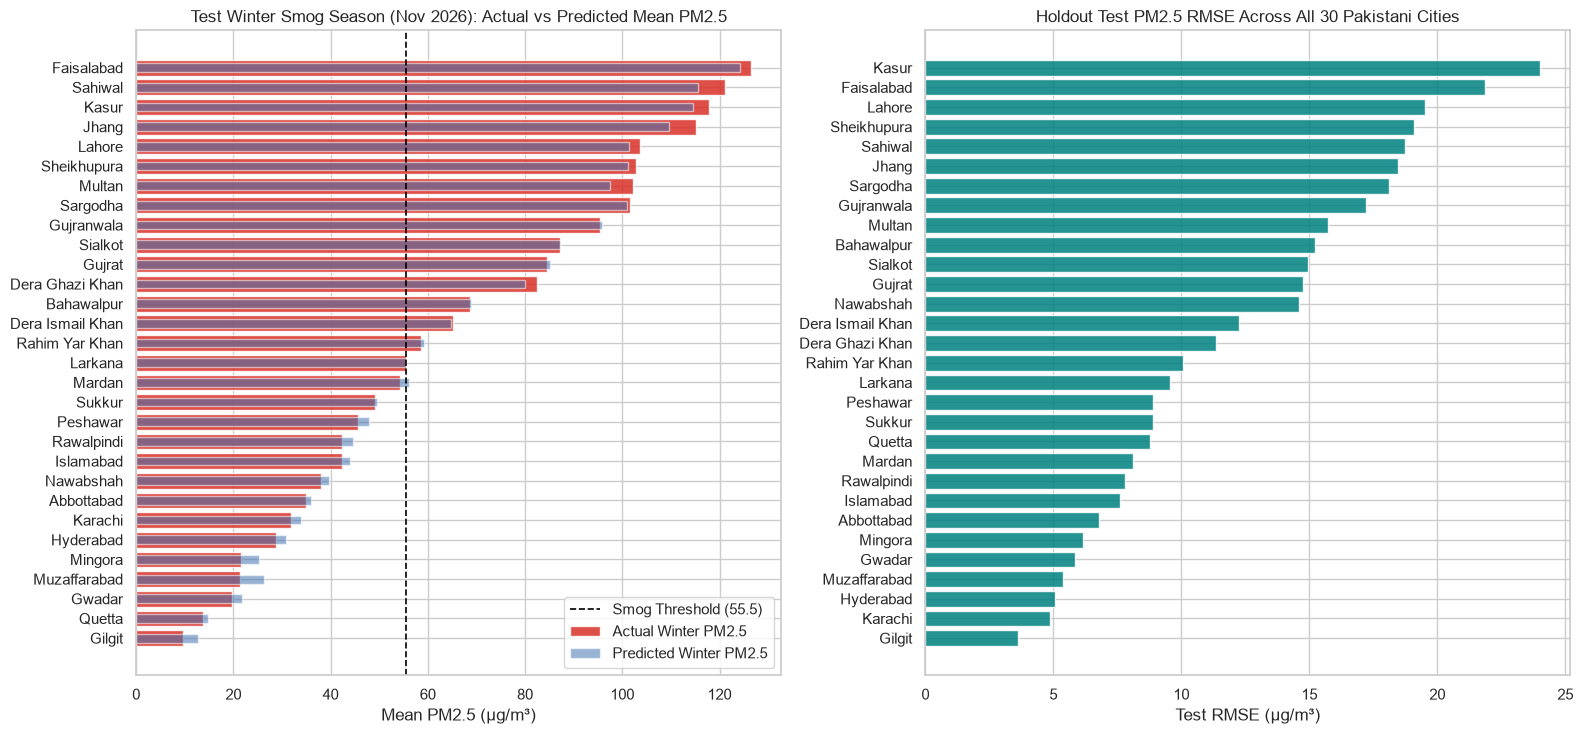

In [7]:
# Diagnostic plots: Validation & Test PM2.5 predictions, residuals, and Smog ROC curve
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

for col_idx, (label, frame, preds, color) in enumerate([
    ('Validation Set', valid_df, pred_val, 'steelblue'),
    ('Test Set', test_df, pred_test, 'darkorange'),
]):
    y_true = frame['target_pm25']
    axes[0, col_idx].scatter(y_true, preds, alpha=0.30, s=14, color=color)
    lims = [0, max(y_true.max(), preds.max())]
    axes[0, col_idx].plot(lims, lims, color='r', linestyle='dashed', lw=1.8, label='Ideal')
    axes[0, col_idx].set_title(f'{label}: Actual vs Predicted Next-Day PM2.5')
    axes[0, col_idx].set_xlabel('Actual PM2.5 (µg/m³)')
    axes[0, col_idx].set_ylabel('Predicted PM2.5 (µg/m³)')
    axes[0, col_idx].legend()

residuals_test = test_df['target_pm25'] - pred_test
axes[1, 0].scatter(pred_test, residuals_test, alpha=0.30, s=14, color='darkorange')
axes[1, 0].axhline(0, color='r', linestyle='dashed', lw=1.8)
axes[1, 0].set_title('Test Set: PM2.5 Residuals')
axes[1, 0].set_xlabel('Predicted PM2.5 (µg/m³)')
axes[1, 0].set_ylabel('Residual (µg/m³)')

fpr_v, tpr_v, _ = roc_curve(valid_df['target_smog_day'], prob_val)
fpr_t, tpr_t, _ = roc_curve(test_df['target_smog_day'], prob_test)
axes[1, 1].plot(fpr_v, tpr_v, lw=2, color='steelblue', label=f"Valid (AUC={roc_auc_score(valid_df['target_smog_day'], prob_val):.4f})")
axes[1, 1].plot(fpr_t, tpr_t, lw=2, color='darkorange', label=f"Test (AUC={roc_auc_score(test_df['target_smog_day'], prob_test):.4f})")
axes[1, 1].plot([0, 1], [0, 1], linestyle='dashed', color='gray')
axes[1, 1].set_title(f'Smog Episode Classifier ROC (PM2.5 >= {SMOG_THRESHOLD_UGM3} µg/m³)')
axes[1, 1].set_xlabel('False Positive Rate')
axes[1, 1].set_ylabel('True Positive Rate')
axes[1, 1].legend(loc='lower right')

plt.tight_layout()
fig.savefig('visualizations/model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# Per-city holdout performance & winter smog exposure summary across all 30 cities
test_eval = test_df[['city', 'province', 'target_pm25', 'target_winter_season']].copy()
test_eval['pred_pm25'] = pred_test
test_eval['pred_smog_prob'] = prob_test

city_metrics_rows = []
for city_name, grp in test_eval.groupby('city'):
    w_grp = grp[grp['target_winter_season'] == 1]
    city_metrics_rows.append({
        'City': str(city_name),
        'Province': str(grp['province'].iloc[0]),
        'Test_RMSE': round(sqrt(mean_squared_error(grp['target_pm25'], grp['pred_pm25'])), 2),
        'Test_MAE': round(mean_absolute_error(grp['target_pm25'], grp['pred_pm25']), 2),
        'Winter_Mean_Actual': round(float(w_grp['target_pm25'].mean()), 2),
        'Winter_Mean_Pred': round(float(w_grp['pred_pm25'].mean()), 2),
    })

city_metrics_df = pd.DataFrame(city_metrics_rows).sort_values('Winter_Mean_Actual', ascending=False).reset_index(drop=True)
display(city_metrics_df.head(15))

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
sorted_cities = city_metrics_df.sort_values('Winter_Mean_Actual', ascending=True)
axes[0].barh(sorted_cities['City'], sorted_cities['Winter_Mean_Actual'], color='#d73027', alpha=0.85, label='Actual Winter PM2.5')
axes[0].barh(sorted_cities['City'], sorted_cities['Winter_Mean_Pred'], color='#4575b4', alpha=0.55, height=0.45, label='Predicted Winter PM2.5')
axes[0].axvline(SMOG_THRESHOLD_UGM3, color='black', linestyle='dashed', linewidth=1.2, label='Smog Threshold (55.5)')
axes[0].set_title('Test Winter Smog Season (Nov 2026): Actual vs Predicted Mean PM2.5')
axes[0].set_xlabel('Mean PM2.5 (µg/m³)')
axes[0].legend(loc='lower right')

rmse_sorted = city_metrics_df.sort_values('Test_RMSE', ascending=True)
axes[1].barh(rmse_sorted['City'], rmse_sorted['Test_RMSE'], color='teal', alpha=0.85)
axes[1].set_title('Holdout Test PM2.5 RMSE Across All 30 Pakistani Cities')
axes[1].set_xlabel('Test RMSE (µg/m³)')

plt.tight_layout()
fig.savefig('visualizations/winter_smog_city_ranking.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Interactive Pakistan Air Quality & Winter Smog Dashboard

Select any of the **30 Pakistani cities** to inspect:
- Next-day (`t+1`) `pm2_5_mean` forecast (`µg/m³`), AQI category, and winter smog episode risk (`%` probability of `PM2.5 >= 55.5 µg/m³`)
- Last 30-day actual vs. predicted time series (`visualizations/city_dashboard_overview.png`) and top 6 pollutant/weather correlations
- All-city next-day forecast summary table and interactive 30-city Folium map exported to `visualizations/pakistan_air_quality_map.html`

In [8]:
loaded_artifact = joblib.load('model/pakistan_aqi_smog_models.pkl')
dash_pm25_model = loaded_artifact['pm25_model']
dash_smog_clf = loaded_artifact['smog_classifier']
dash_features = loaded_artifact['feature_columns']

CITY_COORDINATES: dict[str, tuple[float, float]] = {
    str(row['city']): (float(row['latitude']), float(row['longitude']))
    for _, row in df[['city', 'latitude', 'longitude']].drop_duplicates().iterrows()
}


def pm25_category(val: float) -> tuple[str, str]:
    if val <= 12.0:
        return 'Good', '#2ecc71'
    if val <= 35.4:
        return 'Moderate', '#27ae60'
    if val <= 55.4:
        return 'Unhealthy for Sensitive', '#f39c12'
    if val <= 150.4:
        return 'Unhealthy', '#e67e22'
    if val <= 250.4:
        return 'Very Unhealthy', '#e74c3c'
    return 'Hazardous', '#8e44ad'


all_eng = create_engineered_features(df, include_target=False)
all_eng['pred_next_pm25'] = np.maximum(dash_pm25_model.predict(all_eng[dash_features]), 0)
all_eng['pred_smog_prob'] = dash_smog_clf.predict_proba(all_eng[dash_features])[:, 1]


class CitySummary(TypedDict):
    df: pd.DataFrame
    province: str
    next_date: pd.Timestamp
    next_pred: float
    smog_prob: float
    last_actual: float


city_latest_summary: dict[str, CitySummary] = {}
forecast_rows = []
for city_name, city_group in all_eng.groupby('city'):
    city_group = city_group.sort_values('date')
    latest_date = pd.Timestamp(city_group['date'].iloc[-1])
    next_date = latest_date + pd.Timedelta(days=1)
    next_pred = float(city_group['pred_next_pm25'].iloc[-1])
    smog_prob = float(city_group['pred_smog_prob'].iloc[-1])
    last_actual = float(city_group['pm2_5_mean'].iloc[-1])
    province = str(city_group['province'].iloc[-1])
    cat_name, _ = pm25_category(next_pred)

    city_latest_summary[str(city_name)] = {
        'df': city_group,
        'province': province,
        'next_date': next_date,
        'next_pred': next_pred,
        'smog_prob': smog_prob,
        'last_actual': last_actual,
    }
    forecast_rows.append({
        'City': str(city_name),
        'Province': province,
        'Forecast_Date': next_date.strftime('%Y-%m-%d'),
        'Next_Day_PM25': round(next_pred, 2),
        'Smog_Risk_Pct': round(smog_prob * 100, 1),
        'Last_Actual_PM25': round(last_actual, 2),
        'Category': cat_name,
    })

all_city_forecasts_df = pd.DataFrame(forecast_rows).sort_values('Next_Day_PM25', ascending=False).reset_index(drop=True)
print("Next-Day PM2.5 & Winter Smog Risk Forecast (All 30 Pakistani Cities):")
display(all_city_forecasts_df)

city_dropdown = widgets.Dropdown(
    options=sorted(CITY_COORDINATES.keys()),
    value='Lahore',
    description='City:',
    style={'description_width': '50px'},
)
refresh_btn = widgets.Button(description='Render Dashboard', button_style='primary', icon='chart-line')
dash_output = widgets.Output()


def render_dashboard(_=None):
    with dash_output:
        clear_output()
        city = city_dropdown.value
        info = city_latest_summary[city]
        cat_label, cat_color = pm25_category(info['next_pred'])

        card_html = (
            f'<div style="background:#1f2937;color:#f9fafb;padding:14px 18px;'
            f'border-radius:8px;border-left:6px solid {cat_color};margin-bottom:10px;">'
            f'<h3 style="margin:0 0 6px 0;">{city} ({info["province"]}) - Next-Day PM2.5 & Winter Smog Forecast</h3>'
            f'<div><b>Forecast ({info["next_date"]:%Y-%m-%d}):</b> {info["next_pred"]:.2f} µg/m³ ({cat_label}) | '
            f'<b>Winter Smog Risk:</b> {info["smog_prob"] * 100:.1f}% | '
            f'<b>Last Observed:</b> {info["last_actual"]:.2f} µg/m³</div>'
            f'</div>'
        )
        display(HTML(card_html))

        city_df = info['df']
        n_pts = min(30, len(city_df) - 1)
        ts_dates = city_df['date'].iloc[-n_pts:] + pd.Timedelta(days=1)
        ts_actual = city_df['pm2_5_mean'].shift(-1).iloc[-n_pts:]
        ts_pred = city_df['pred_next_pm25'].iloc[-n_pts:]

        fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})
        axes[0].plot(ts_dates, ts_actual, label='Actual (t+1)', linewidth=2, color='steelblue')
        axes[0].plot(ts_dates, ts_pred, label='Predicted (t+1)', linewidth=2, color='darkorange', alpha=0.85)
        axes[0].axhline(SMOG_THRESHOLD_UGM3, color='crimson', linestyle='dashed', linewidth=1.2, label='Smog Threshold (55.5)')
        axes[0].set_title(f'{city} - Last 30 Days: Actual vs Predicted Next-Day PM2.5')
        axes[0].set_ylabel('PM2.5 (µg/m³)')
        axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
        axes[0].tick_params(axis='x', rotation=35)
        axes[0].legend()

        corr_cols = [c for c in analysis_cols if c != 'pm2_5_mean']
        city_raw = df[df['city'] == city]
        city_corr = city_raw[corr_cols + ['pm2_5_mean']].corr()['pm2_5_mean'].drop('pm2_5_mean')
        top6 = city_corr.reindex(city_corr.abs().sort_values(ascending=False).head(6).index)
        bar_colors = ['#ef553b' if v > 0 else '#1b9e77' for v in top6.values]
        axes[1].barh(top6.index, top6.abs().values, color=bar_colors)
        axes[1].invert_yaxis()
        axes[1].set_title('Top 6 Pollutant & Weather Correlations')
        axes[1].set_xlabel('|Pearson r|')

        plt.tight_layout()
        fig.savefig('visualizations/city_dashboard_overview.png', dpi=150, bbox_inches='tight')
        plt.show()

        aq_map = folium.Map(location=[30.3753, 69.3451], zoom_start=5, tiles='Esri.WorldTopoMap')
        for name, (lat, lon) in CITY_COORDINATES.items():
            if name not in city_latest_summary:
                continue
            c_info = city_latest_summary[name]
            c_cat, c_color = pm25_category(c_info['next_pred'])
            popup_html = (
                f"<b>{name}</b> ({c_info['province']})<br>"
                f"Next-Day Pred ({c_info['next_date']:%Y-%m-%d}): {c_info['next_pred']:.2f} µg/m³ ({c_cat})<br>"
                f"Winter Smog Risk: {c_info['smog_prob'] * 100:.1f}%<br>"
                f"Last Actual: {c_info['last_actual']:.2f} µg/m³"
            )
            folium.CircleMarker(
                location=[lat, lon],
                radius=10 if name == city else 6,
                color=c_color,
                fill=True,
                fill_color=c_color,
                fill_opacity=0.85,
                popup=folium.Popup(popup_html, max_width=280),
            ).add_to(aq_map)

        map_path = 'visualizations/pakistan_air_quality_map.html'
        aq_map.save(map_path)
        display(IFrame(src=map_path, width='100%', height='450px'))


refresh_btn.on_click(render_dashboard)
display(widgets.HBox([city_dropdown, refresh_btn]), dash_output)
render_dashboard()

Next-Day PM2.5 & Winter Smog Risk Forecast (All 30 Pakistani Cities):


,City,Province,Forecast_Date,Next_Day_PM25,Smog_Risk_Pct,Last_Actual_PM25,Category
0,Faisalabad,Punjab,2026-11-25,156.97,100.0,114.28,Very Unhealthy
1,Jhang,Punjab,2026-11-25,142.21,100.0,148.92,Unhealthy
2,Sahiwal,Punjab,2026-11-25,130.48,100.0,127.03,Unhealthy
3,Kasur,Punjab,2026-11-25,128.91,100.0,89.58,Unhealthy
4,Sargodha,Punjab,2026-11-25,125.30,100.0,90.28,Unhealthy
5,Sialkot,Punjab,2026-11-25,112.41,100.0,97.13,Unhealthy
6,Sheikhupura,Punjab,2026-11-25,109.76,100.0,74.00,Unhealthy
7,Gujrat,Punjab,2026-11-25,109.16,100.0,93.16,Unhealthy
8,Gujranwala,Punjab,2026-11-25,101.28,99.9,68.82,Unhealthy
9,Lahore,Punjab,2026-11-25,100.68,99.9,75.57,Unhealthy


Output()